In [2]:
# Dataset exploration
## Objective
This notebook explores the interior design dataset before any preprocessing or modeling.
-- understand the folder structure
-- count image per room and style
-- inspect image sizes
--visualize sample images
-- detect corrupted images
-- generate summary statistics

SyntaxError: invalid syntax (622712520.py, line 3)

In [3]:
from pathlib import Path # it handles file paths
from collections import Counter # for counting categories
import random # to pick random sample images
import pandas as pd # it stores metadata in tables
import matplotlib.pyplot as plt # to display charts or images
from PIL import Image # to open image files

In [4]:
DATASET_DIR = Path("C:\\Users\\Khushi Trivedi\\visual-retrieval-system\\data\\raw\\images") 
print(DATASET_DIR)
print(DATASET_DIR.exists())

C:\Users\Khushi Trivedi\visual-retrieval-system\data\raw\images
True


In [5]:
from pathlib import Path

print(Path.cwd())

c:\Users\Khushi Trivedi\visual-retrieval-system\notebooks


In [6]:
for folder in DATASET_DIR.iterdir():
    print(folder.name)

bathroom
bedroom
kitchen
living_room


In [7]:
for room_folder in DATASET_DIR.iterdir():
    print(room_folder.name)

    for style_folder in room_folder.iterdir():
        print("  ", style_folder.name)

bathroom
   boho
   industrial
   minimalist
   modern
   scandinavian
bedroom
   boho
   industrial
   minimalist
   modern
   scandinavian
kitchen
   boho
   industrial
   minimalist
   modern
   scandinavian
living_room
   boho
   industrial
   minimalist
   modern
   scandinavian


In [8]:
metadata = []

for room_folder in DATASET_DIR.iterdir():
    if not room_folder.is_dir():
        continue

    room = room_folder.name 

    for style_folder in room_folder.iterdir():
        if not style_folder.is_dir():
            continue

        style = style_folder.name 

        for image_path in style_folder.glob("*"):
            if image_path.suffix.lower() not in [".jpg",".png",".jpeg"]:
                continue

            metadata.append(
                {
                    "room": room,
                    "style": style,
                    "path": str(image_path) 
                }
            )



In [9]:
df = pd.DataFrame(metadata)
df.head()

,room,style,path
0,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...
1,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...
3,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...
4,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...


In [10]:
len(df)


4139

In [11]:
df.sample(5)

,room,style,path
1520,bedroom,scandinavian,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2493,kitchen,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2638,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...
12,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2288,kitchen,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4139 entries, 0 to 4138
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   room    4139 non-null   str  
 1   style   4139 non-null   str  
 2   path    4139 non-null   str  
dtypes: str(3)
memory usage: 97.1 KB


In [13]:
widths = []
heights = []

for row in df.itertuples():

    with Image.open(row.path) as image:
        width, height = image.size

        widths.append(width)
        heights.append(height)

df["width"] = widths
df["height"] = heights

In [14]:
df.head()

,room,style,path,width,height
0,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,421
1,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,472
2,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236
3,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,183,275
4,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,251,201


In [15]:
df.sample(5)

,room,style,path,width,height
2091,kitchen,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236
2725,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,720,1280
3432,living_room,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,313
3497,living_room,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236
2592,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,233


In [16]:
df[["width","height"]].describe()

,width,height
count,4139.000000,4139.000000
mean,240.192559,334.928727
std,57.321112,127.285535
min,168.000000,123.000000
25%,236.000000,293.500000
50%,236.000000,350.000000
75%,236.000000,354.000000
max,1280.000000,2276.000000


In [17]:
room_counts = df["room"].value_counts()
print(room_counts)

room
kitchen        1498
living_room    1056
bedroom         881
bathroom        704
Name: count, dtype: int64


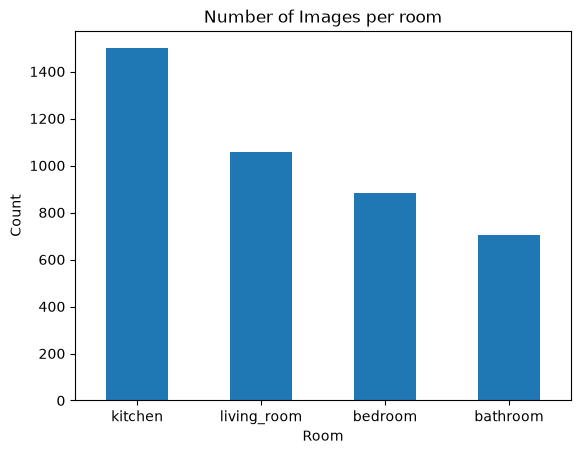

In [29]:
room_counts.plot(kind = "bar")
plt.title("Number of Images per room")
plt.xlabel("Room")
plt.ylabel("Count")
plt.xticks(rotation = 360)
plt.show()

In [19]:
style_counts = df["style"].value_counts()
print(style_counts)

style
modern          1026
boho             918
industrial       859
minimalist       744
scandinavian     592
Name: count, dtype: int64


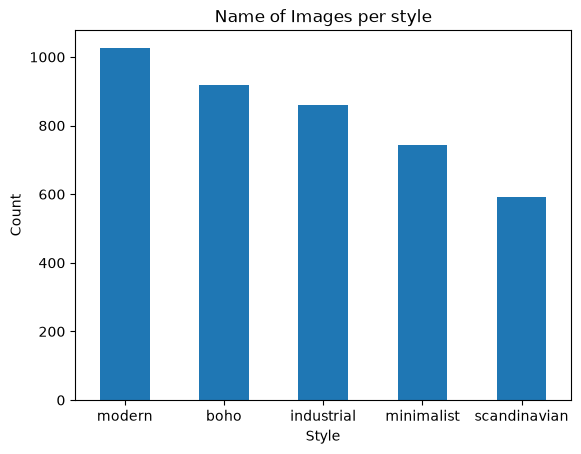

In [28]:
style_counts.plot(kind="bar")
plt.title("Name of Images per style")
plt.xlabel("Style")
plt.ylabel("Count")
plt.xticks(rotation =360)
plt.show()

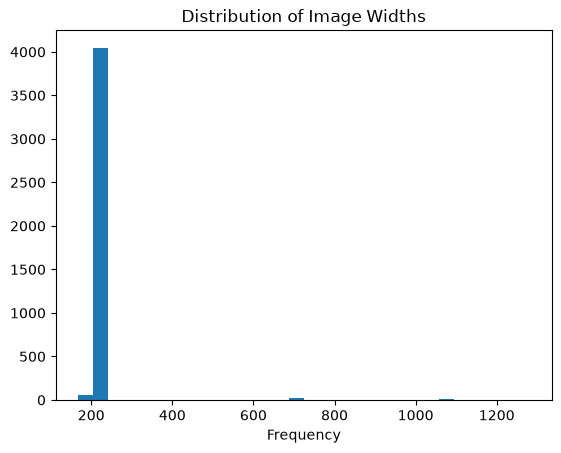

In [30]:
plt.hist(df["width"], bins=30)

plt.title("Distribution of Image Widths")
plt.xlabel("Width")
plt.xlabel("Frequency")
plt.show()

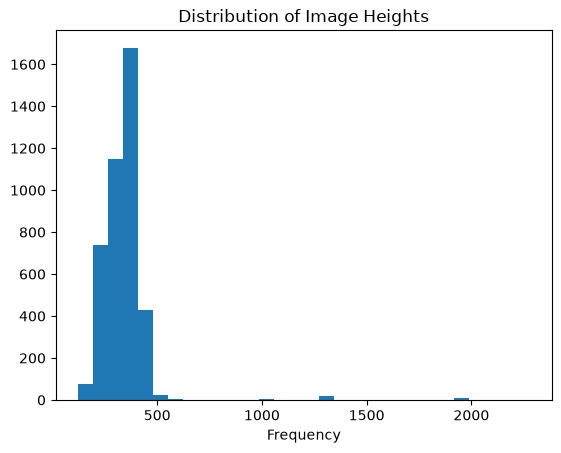

In [31]:
plt.hist(df["height"], bins=30)

plt.title("Distribution of Image Heights")
plt.xlabel("Height")
plt.xlabel("Frequency")
plt.show()

In [33]:
df["aspect_ratio"]=df["width"]/df["height"]
df["aspect_ratio"].describe()

count    4139.000000
mean        0.753294
std         0.170752
min         0.170397
25%         0.666667
50%         0.668555
75%         0.800797
max         1.902439
Name: aspect_ratio, dtype: float64

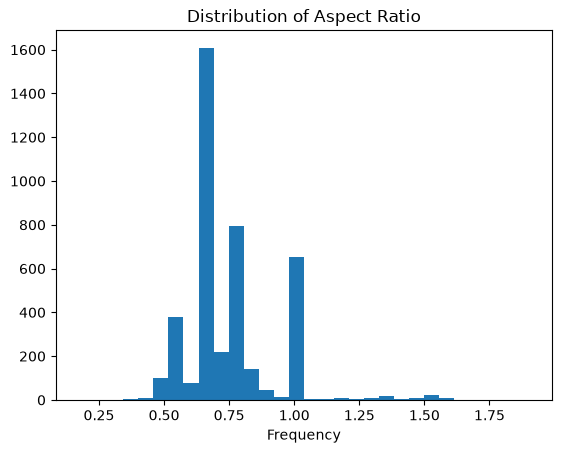

In [34]:
plt.hist(df["aspect_ratio"], bins=30)

plt.title("Distribution of Aspect Ratio")
plt.xlabel("Width/Height")
plt.xlabel("Frequency")
plt.show()

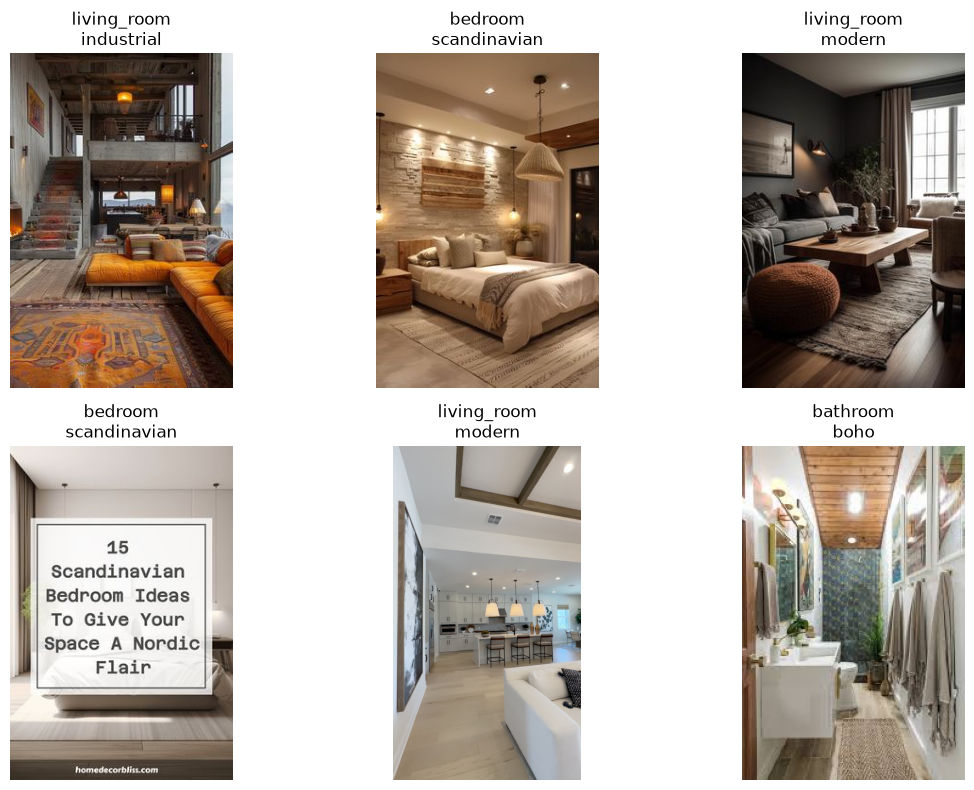

In [36]:
fig, axes = plt.subplots(2,3,figsize=(12,8))
samples = df.sample(6).reset_index(drop = True)
for ax, row in zip(axes.flat, samples.itertuples()):
   with Image.open(row.path) as image:
      ax.imshow(image)

   ax.set_title(f"{row.room}\n{row.style}")
   ax.axis("off")

plt.tight_layout()
plt.show()

In [37]:
corrupted =[]
for row in df.itertuples():
    try:
        with Image.open(row.path) as image:
            image.verify()

    except Exception:
        corrupted.append(row.path)

In [38]:
print(f"Corrupted images: {len(corrupted)}")

Corrupted images: 0


In [39]:
df.to_csv("../data/processed/image_metadata.csv", index=False)

In [40]:
df = pd.read_csv("../data/processed/image_metadata.csv")

In [41]:
print(df[["width","height"]].describe())

             width       height
count  4139.000000  4139.000000
mean    240.192559   334.928727
std      57.321112   127.285535
min     168.000000   123.000000
25%     236.000000   293.500000
50%     236.000000   350.000000
75%     236.000000   354.000000
max    1280.000000  2276.000000


In [42]:
print(df["aspect_ratio"].describe())

count    4139.000000
mean        0.753294
std         0.170752
min         0.170397
25%         0.666667
50%         0.668555
75%         0.800797
max         1.902439
Name: aspect_ratio, dtype: float64


# Dataset findings
## Overview
- Total images: 4139
- Room Categories: 4
- Style categories: 4
- No corrupted image found 
##Image characteristics
- Average width:240.192559   
-Average height:334.928727
- Aspect ratios are not uniform
- Most images have similar dimensions with a few large outliers

## Observations
- A small number of inforgraphic/ text-heavy Pinterest images are present
- Dataset appears suitable for image retrieval experiments.
- Images may need resizing before embedding extraction.